# 02 — Khám phá thông số AI4I

Thống kê mô tả toàn nguồn trước khi có split; không tối ưu mô hình trên dữ liệu này. Quan hệ phân biệt hỏng/bình thường, lựa chọn biến và tham số phải được kiểm tra trên tập phát triển theo giao thức sẽ chốt. UDI/thứ tự dòng không phải thời gian đo.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "configs/ai4i-schema.json").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Mở notebook bên trong repository dự án.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from maintenance.quality import analyze, export_analysis, plot_analysis
result = analyze(ROOT)


In [2]:
display(result["numeric_summary"])
display(result["iqr_flags"])
display(result["source_order"])

,count,mean,std,min,25%,50%,75%,max
air_temperature_k,10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
process_temperature_k,10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
rotational_speed_rpm,10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
torque_nm,10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
tool_wear_min,10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


,outside_1_5_iqr
air_temperature_k,0
process_temperature_k,0
rotational_speed_rpm,418
torque_nm,69
tool_wear_min,0


,lag1_source_order
air_temperature_k,0.999417
process_temperature_k,0.998550
rotational_speed_rpm,0.007667
torque_nm,0.005399
tool_wear_min,0.930594


In [3]:
display(result["pearson"])
display(result["spearman"])

,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
air_temperature_k,1.000000,0.876107,0.022670,-0.013778,0.013853
process_temperature_k,0.876107,1.000000,0.019277,-0.014061,0.013488
rotational_speed_rpm,0.022670,0.019277,1.000000,-0.875027,0.000223
torque_nm,-0.013778,-0.014061,-0.875027,1.000000,-0.003093
tool_wear_min,0.013853,0.013488,0.000223,-0.003093,1.000000


,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
air_temperature_k,1.000000,0.864217,0.013732,-0.011765,0.013495
process_temperature_k,0.864217,1.000000,0.016985,-0.014488,0.013702
rotational_speed_rpm,0.013732,0.016985,1.000000,-0.916474,0.003168
torque_nm,-0.011765,-0.014488,-0.916474,1.000000,-0.003887
tool_wear_min,0.013495,0.013702,0.003168,-0.003887,1.000000


## Biểu đồ mô tả

IQR chỉ đánh dấu giá trị xa vùng trung tâm, chưa kết luận lỗi. Tương quan không chứng minh nhân quả; Pearson/Spearman không chứng minh độc lập khi gần 0. Tự tương quan theo thứ tự nguồn là cảnh báo phụ thuộc, không phải bằng chứng thời gian báo trước hỏng.

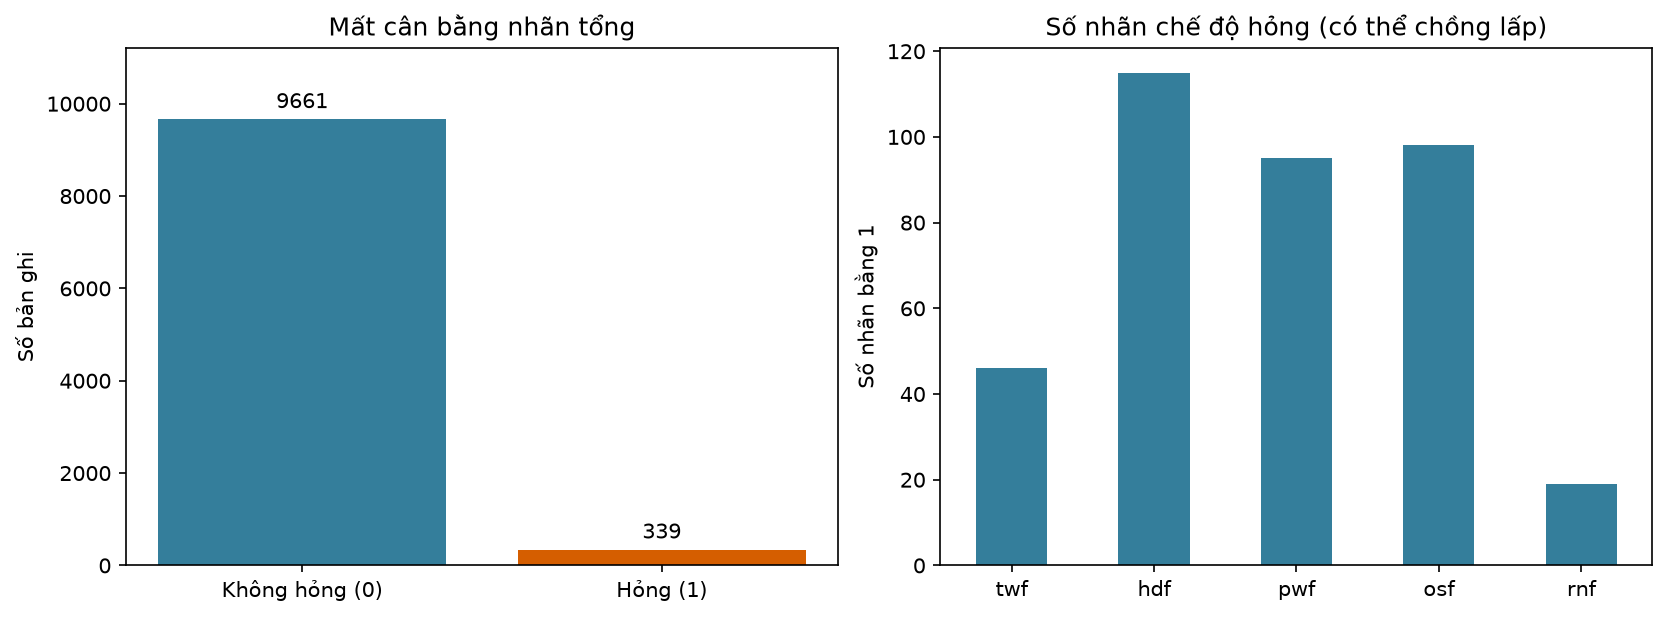

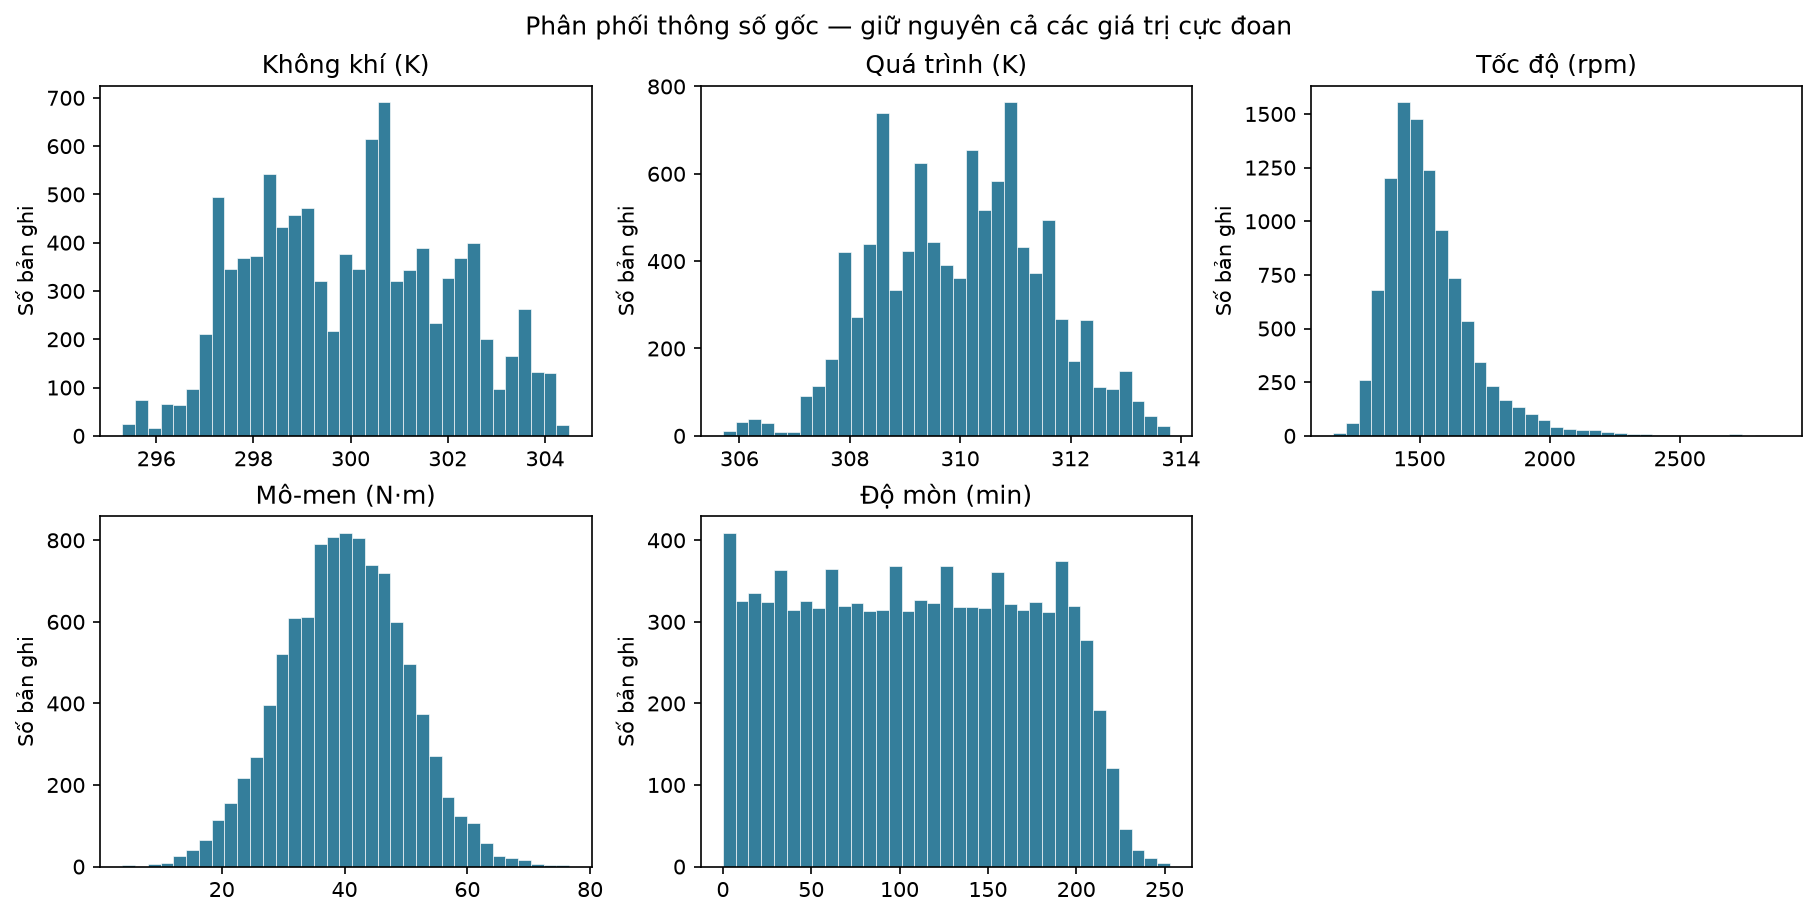

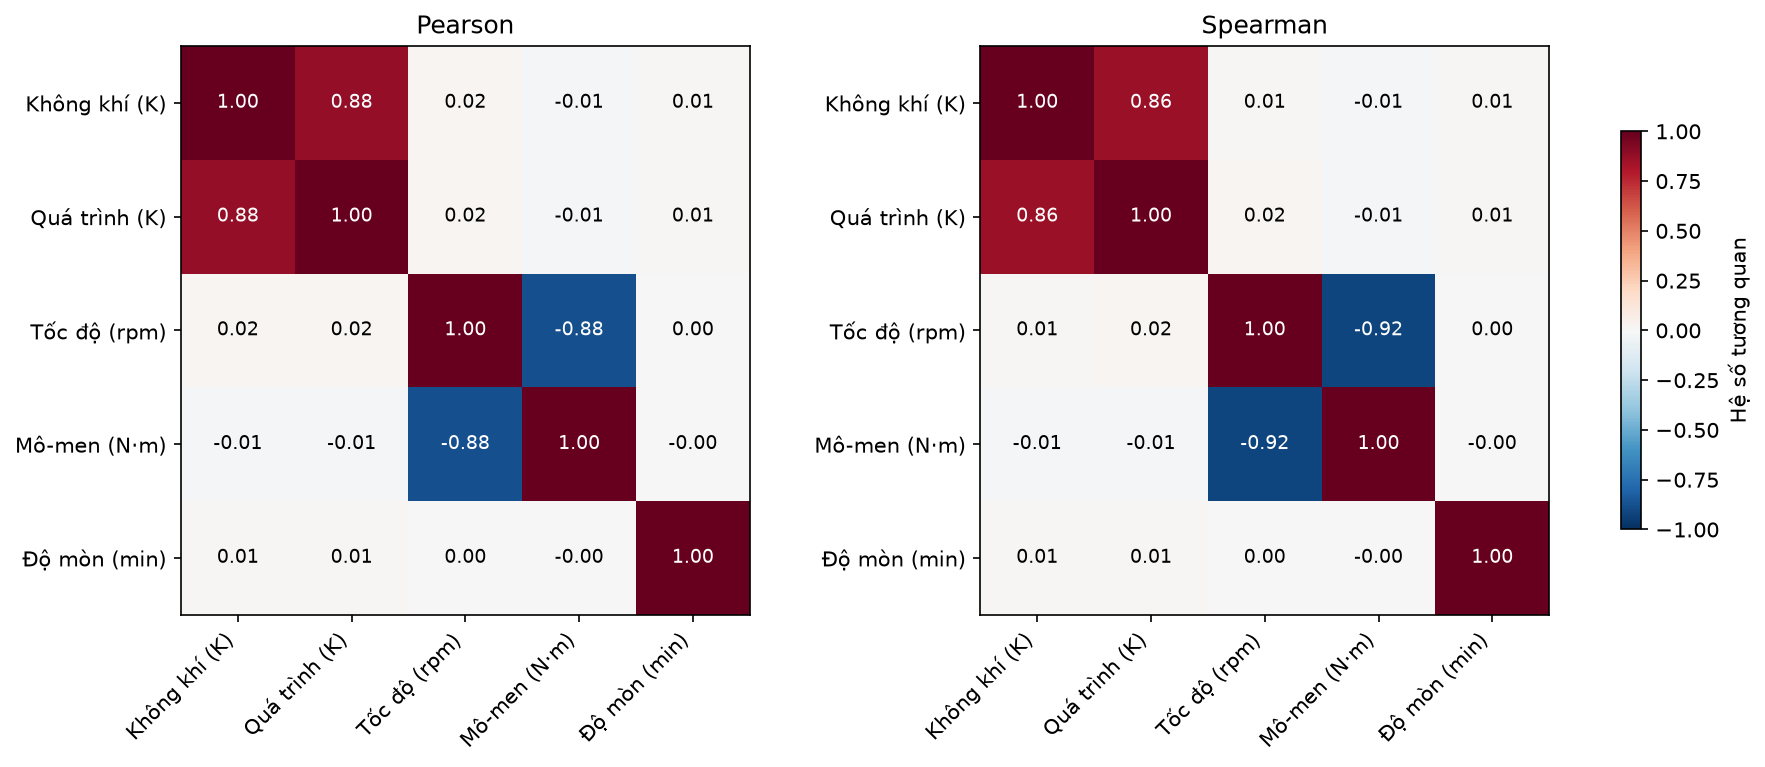

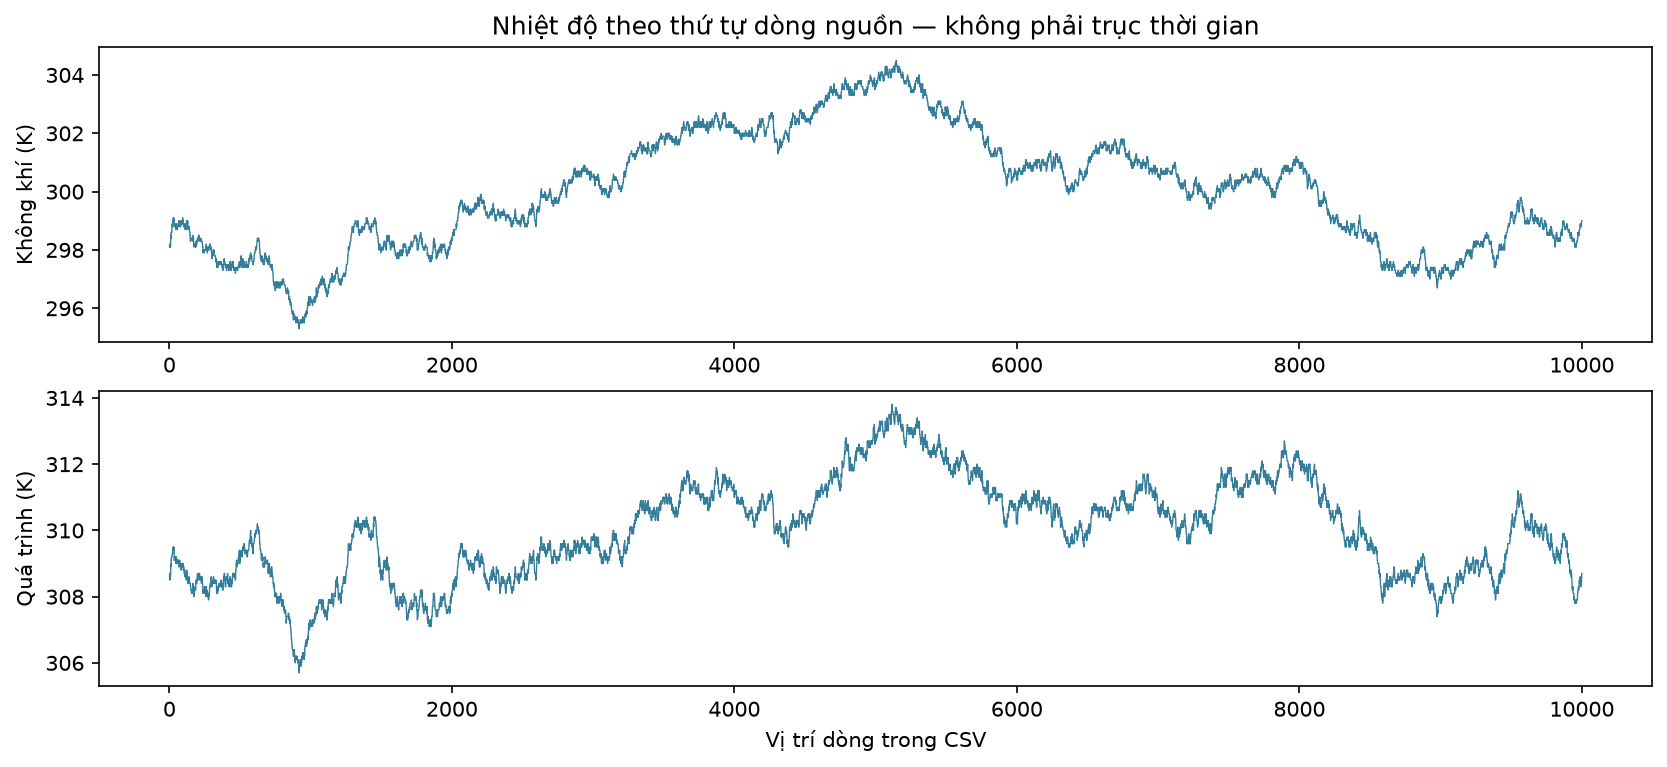

In [4]:
from IPython.display import Image, display
for path in plot_analysis(result, ROOT):
    display(Image(filename=str(path)))

## Giới hạn

Các biểu đồ này là EDA, chưa thay dashboard Superset và không chứa kết quả mô hình. Chưa có lead time hoặc thử nghiệm độc lập ngoài dữ liệu mô phỏng. Thiết kế split cần xem xét phụ thuộc theo thứ tự nguồn, không chỉ chia ngẫu nhiên rồi mặc định các mẫu độc lập.